In [1]:
25 in [12,24,25,12]

True

review more on this topics plus some exereimental exercises and even the rigorouse matha analysis...or just ask AI ;)

- view sequqntial search, orders and unorderd

then view binary search 
- When we split the list enough times, we end up with a list that has just one item. Either that is the item we are looking for or it is not. Either way, we are done. The number of comparisons necessary to get to this point is 𝑖 where 
𝑛
2𝑖
 
 =1. Solving for 𝑖 gives us 𝑖 =log⁡𝑛. The maximum number of comparisons is logarithmic with respect to the number of items in the list. Therefore, the binary search is 𝑂⁡(log⁡𝑛).

In [2]:
def binary_search(a_list, item):
    """
    Performs a binary search to find if an item exists in a sorted list.
    Returns True if found, False otherwise.
    """
    first = 0
    last = len(a_list) - 1

    # Continue searching while the search space contains elements
    while first <= last:
        # Find the middle index of the current range
        midpoint = (first + last) // 2
        
        # Check if the item is at the midpoint
        if a_list[midpoint] == item:
            return True
        # If the item is smaller, ignore the right half
        elif item < a_list[midpoint]:
            last = midpoint - 1
        # If the item is larger, ignore the left half
        else:
            first = midpoint + 1
            
    # Return False if the item was not found in the list
    return False


# Test data (The list must be sorted for binary search to work)
test_list = [0, 1, 2, 8, 13, 17, 19, 32, 42]

# Execute and print test cases
print(binary_search(test_list, 3))   # Expected output: False
print(binary_search(test_list, 13))  # Expected output: True


False
True


 A Note on Performance:While this recursive version looks very clean, slicing a list in Python (a_list[:midpoint]) creates a brand-new copy of that slice. This means the code takes up extra memory and time behind the scenes, making its overall time complexity \(O(N)\) instead of the ideal \(O(\log N)\). Would you like me to show you how to write a memory-efficient recursive binary search that passes indices instead of copying the list?

In [3]:
def binary_search_rec(a_list, item):
    """
    Performs a recursive binary search to find an item in a sorted list.
    Returns True if found, False otherwise.
    """
    # Base Case 1: The list is empty, item is not present
    if len(a_list) == 0:
        return False
        
    # Find the middle index of the current list slice
    midpoint = len(a_list) // 2
    
    # Base Case 2: The item is found at the midpoint
    if a_list[midpoint] == item:
        return True
    # Recursive Case 1: Item is smaller, search the left half
    elif item < a_list[midpoint]:
        return binary_search_rec(a_list[:midpoint], item)
    # Recursive Case 2: Item is larger, search the right half
    else:
        return binary_search_rec(a_list[midpoint + 1 :], item)


# Test data (The list must be sorted for binary search to work)
test_list = [0, 1, 2, 8, 13, 17, 19, 32, 42]

# Execute and print test cases
print(binary_search_rec(test_list, 3))   # Expected output: False
print(binary_search_rec(test_list, 13))  # Expected output: True


False
True


In [4]:
def binary_search_rec_efficient(a_list, item, low=0, high=None):
    """
    Performs a memory-efficient recursive binary search using indices.
    Avoids list slicing to maintain O(log n) time complexity.
    """
    # Initialize high pointer on the first call
    if high is None:
        high = len(a_list) - 1

    # Base Case 1: Search space is exhausted, item not found
    if low > high:
        return False

    # Find the middle index between low and high
    midpoint = (low + high) // 2

    # Base Case 2: Item found
    if a_list[midpoint] == item:
        return True
    # Recursive Case 1: Search the left half
    elif item < a_list[midpoint]:
        return binary_search_rec_efficient(a_list, item, low, midpoint - 1)
    # Recursive Case 2: Search the right half
    else:
        return binary_search_rec_efficient(a_list, item, midpoint + 1, high)


# Test data
test_list = [0, 1, 2, 8, 13, 17, 19, 32, 42]

# Execute and print test cases
print(binary_search_rec_efficient(test_list, 3))   # Expected output: False
print(binary_search_rec_efficient(test_list, 13))  # Expected output: True


False
True


### Implementing the Map Abstract Data Type


example fo a hash table

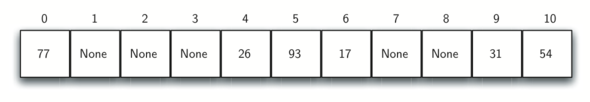

so we have lithe three or two raws:
say we have m as size of the hash table to store keys
- slots numbers 0 to m-1. these represent the hash value whis is computed by hash function just for insexing
- then the slot number is used to store the key??
- the data

In [5]:

class HashTable:
    def __init__(self):
         # Although this is arbitrary, 
        #it is important that the size be a prime number
        #so that the collision resolution algorithm can be as efficient as possible.
        self.size = 11
        self.slots = [None] * self.size # We will treat the key list as a hash table. These are slots for key values
        # so in short we are serching for keys the use the keys to get data
        self.data = [None] * self.size # cre

    def hash_function(self, key, size):
        return key % size #this hash_function implements the simple remainder method...computes which slot the key value get

    def rehash(self, old_hash, size):
        #you can review how the operator '%' works, is 9%10 = 19%10 = 9
        return (old_hash + 1) % size #The collision resolution technique is linear probing with a “plus 1” rehash value 

    def put(self, key, data):
        #assumes that there will eventually be an empty slot unless the key is already present in the self.slots
        
        hash_value = self.hash_function(key, len(self.slots)) 

        if self.slots[hash_value] is None:
            self.slots[hash_value] = key
            self.data[hash_value] = data
        else:
            if self.slots[hash_value] == key:
                self.data[hash_value] = data  # replace
            else:
                #iterates the rehash function until an empty slot occurs.
                next_slot = self.rehash(hash_value, len(self.slots)) 
                while (
                    self.slots[next_slot] is not None
                    and self.slots[next_slot] != key
                ):
                    next_slot = self.rehash(next_slot, len(self.slots))

                if self.slots[next_slot] is None:
                    self.slots[next_slot] = key
                    self.data[next_slot] = data
                else:
                    ##If a nonempty slot already contains the key, the old data value is replaced with the new data value.
                    self.data[next_slot] = data

    

    def get(self, key):
        start_slot = self.hash_function(key, len(self.slots))

        position = start_slot
        while self.slots[position] is not None:
            if self.slots[position] == key:
                return self.data[position]
            else:
                position = self.rehash(position, len(self.slots))
                #then we guarantees that the search will terminate by checking to make sure that we have not returned to the initial slot
                if position == start_slot:
                    return None

    def __getitem__(self, key):
        return self.get(key)

    def __setitem__(self, key, data):
        self.put(key, data)

h = HashTable()
h[54] = "cat"
h[26] = "dog"
h[93] = "lion"
h[17] = "tiger"
h[77] = "bird"
h[31] = "cow"
h[44] = "goat"
h[55] = "pig"
h[20] = "chicken"
print(h.slots)
print(h.data)
print(h[20])
print(h[17])
h[20] = "duck"
print(h[20])
print(h[99])


[77, 44, 55, 20, 26, 93, 17, None, None, 31, 54]
['bird', 'goat', 'pig', 'chicken', 'dog', 'lion', 'tiger', None, None, 'cow', 'cat']
chicken
tiger
duck
None


In [6]:
9%10 == 19%10 == 9

True

**search more ont the Analysis of Hashing**

### Sorting

#### Bubble sort
Bubble Sort Visually Explained | Sorting Algorithm | Computer Science by ByteQuest: https://youtu.be/0qqf8_ZtCrc?si=O9xmibnX1QMgh4Zf


In [7]:
def bubble_sort(a_list):
    # Outer loop controls the range of elements to be compared.
    # It starts at the last index (len(a_list) - 1) and counts down to 1 (stops before 0).
            #range(start, stop, step)
    # Why? Each full pass guarantees the largest unsorted element "bubbles" to its correct position at the end.
    # So, with each step, the unsorted section shrinks by 1 from right to left.
    for i in range(len(a_list) - 1, 0, -1):
        
        # Inner loop compares adjacent pairs within the unsorted portion of the list.
        # It loops from index 0 up to, but not including, index i.
        # Why range(i)? Because everything at or after index i is already perfectly sorted.
        for j in range(i):
            
            # Check if the current element is larger than the next element
            if a_list[j] > a_list[j + 1]:
                # Swap the elements to bring the larger one forward
                # Note that we could also have used the simultaneous assignment to swap the items like: a, b = b, a
                temp = a_list[j]
                a_list[j] = a_list[j + 1]
                a_list[j + 1] = temp


# Test data (Unsorted list)
a_list = [54, 26, 93, 17, 77, 31, 44, 55, 20]

# Execute the sort (modifies the list in-place)
bubble_sort(a_list)

# Print the sorted result
print(a_list)  # Output: [17, 20, 26, 31, 44, 55, 54, 77, 93]


[17, 20, 26, 31, 44, 54, 55, 77, 93]


In [8]:
for i in range(5, 0, -1):
    print(i)
# Output: 5, 4, 3, 2, 1


5
4
3
2
1


In [9]:
#The code below shows this modification, which is often referred to as the short bubble
def bubble_sort_short(a_list):
    for i in range(len(a_list) - 1, 0, -1):
        exchanges = False
        for j in range(i):
            if a_list[j] > a_list[j + 1]:
                exchanges = True
                a_list[j], a_list[j + 1] = a_list[j + 1], a_list[j]
        if not exchanges:
            break


a_list = [20, 30, 40, 90, 50, 60, 70, 80, 100, 110]
bubble_sort_short(a_list)
print(a_list)


[20, 30, 40, 50, 60, 70, 80, 90, 100, 110]


#### Selection Sort

see demo here: Selection Sort Visually Explained | Sorting Algorithm | Computer Science by ByteQuest: https://youtu.be/hgbnER_D0L8?si=PmCP7ffq7yVjAolY

In [10]:
def selection_sort(a_list):
    # Outer loop controls how many passes we make through the list.
    # With each pass 'i', the unsorted portion of the list shrinks by 1 from the right.
    for i in range(len(a_list)):
        
        # Assume the element at index 0 holds the maximum value for this pass
        mx_idx = 0
        
        # Inner loop searches the unsorted portion of the list.
        # The range is len(a_list) - i because the last 'i' elements are already sorted.
        for j in range(len(a_list) - i):
            # If we find an element larger than our current maximum, update mx_idx
            if a_list[j] > a_list[mx_idx]:
                mx_idx = j
                
        # Calculate the proper end target index where the maximum value belongs.
        # This is the last index of the current unsorted section.
        new_end = len(a_list) - i - 1
        
        # Swap the maximum value found into its correct location at the end of the section.
        # Only swap if the maximum isn't already sitting in the correct end position.
        if mx_idx != new_end:
            a_list[mx_idx], a_list[new_end] = a_list[new_end], a_list[mx_idx]

            
# Test data (Unsorted list)
a_list = [54, 26, 93, 17, 77, 31, 44, 55, 20]

# Execute the sort (modifies the list in-place)
selection_sort(a_list)

# Print the sorted result
print(a_list)  # Output: [17, 20, 26, 31, 44, 54, 55, 77, 93]


[17, 20, 26, 31, 44, 54, 55, 77, 93]


#### The Insertion Sort

Insertion Sort Visually Explained | Sorting Algorithm | Computer Science by ByteQuest: https://youtu.be/WtD9NeSPfAw?si=YUAqzWQYnLSLZ9hY

In [11]:
def insertion_sort(a_list):
    # Outer loop starts at index 1 and moves right to the end of the list.
    # We assume the first element (index 0) is a already a "sorted sublist" of size 1.
    for i in range(1, len(a_list)): # it might help to thing in terms of x_i and x_{i-1}
        # Record the current item to be inserted into the sorted portion
        cur_val = a_list[i]
        # Keep track of the current position we are evaluating
        cur_pos = i

        # Inner loop shifts elements of the sorted sublist to the right.
        # It continues as long as we haven't hit the beginning of the list (cur_pos > 0)
        # AND the element to the left is larger than the value we are trying to insert.
        while cur_pos > 0 and a_list[cur_pos - 1] > cur_val:
            # Shift the larger element one position to the right
            a_list[cur_pos] = a_list[cur_pos - 1]
            # Move our position tracking pointer one step to the left
            cur_pos = cur_pos - 1
            
        # Drop the current value into its final, correct sorted position
        a_list[cur_pos] = cur_val


# Test data (Unsorted list)
a_list = [54, 26, 93, 17, 77, 31, 44, 55, 20]

# Execute the sort (modifies the list in-place)
insertion_sort(a_list)

# Print the sorted result
print(a_list)  # Output: [17, 20, 26, 31, 44, 54, 55, 77, 93]


[17, 20, 26, 31, 44, 54, 55, 77, 93]


#### The Shell Sort
Shell Sort - Data Structures & Algorithms Tutorial Python #18
codebasics: https://youtu.be/VxNr9Vudp4Y?si=5LOOVKwT69scxZ7c

In [12]:
def shell_sort(a_list):
    # Establish the initial increment/gap size as n // 2.
    # This divides the list conceptually into n // 2 interleaved sublists.
    sublist_count = len(a_list) // 2
    
    # Continue processing until the gap size reaches 0
    while sublist_count > 0:
        # Loop through each of the independent sublists created by the gap.
        # For example, if gap is 4, pos_start will be 0, 1, 2, and 3.
        for pos_start in range(sublist_count):
            # Perform a modified insertion sort on the current sublist
            gap_insertion_sort(a_list, pos_start, sublist_count)
            
        print("After increments of size", sublist_count, "the list is", a_list)
        
        # Reduce the gap size by half for the next pass.
        # The final pass will always be a gap of 1 (a standard insertion sort).
        sublist_count = sublist_count // 2


def gap_insertion_sort(a_list, start, gap):
    # Standard insertion sort, but instead of moving by 1, we jump by 'gap' steps.
    # The loop starts at the second element of the sublist (start + gap).
    for i in range(start + gap, len(a_list), gap):
        cur_val = a_list[i]  # Current item to be positioned
        cur_pos = i          # Position tracking pointer
        
        # Shift elements of the sublist to the right by 'gap' steps.
        # Continues as long as there is an element to the left (cur_pos >= gap)
        # AND that element is larger than our current value.
        while cur_pos >= gap and a_list[cur_pos - gap] > cur_val:
            a_list[cur_pos] = a_list[cur_pos - gap]  # Shift element right
            cur_pos = cur_pos - gap                  # Move pointer left
            
        # Drop the current value into its correct sorted position within this sublist
        a_list[cur_pos] = cur_val


# Test data (Unsorted list)
a_list = [54, 26, 93, 17, 77, 31, 44, 55, 20]

# Execute the shell sort
shell_sort(a_list)

# Print the final sorted result
print("Final sorted list:", a_list)


After increments of size 4 the list is [20, 26, 44, 17, 54, 31, 93, 55, 77]
After increments of size 2 the list is [20, 17, 44, 26, 54, 31, 77, 55, 93]
After increments of size 1 the list is [17, 20, 26, 31, 44, 54, 55, 77, 93]
Final sorted list: [17, 20, 26, 31, 44, 54, 55, 77, 93]


##### Playground

In [13]:
[i for i in range(3,7,3)]


[3, 6]

In [14]:
def shell_sort(a_list):
    # Establish the initial increment/gap size as n // 2.
    # This divides the list conceptually into n // 2 interleaved sublists.
    print ('len of list= ',len(a_list))
    sublist_count = len(a_list) // 2
    print('initial sublist count =', sublist_count)
    print("then we assume first psotion is already sorted just like the regular insertion sort" )
    
    # Continue processing until the gap size reaches 0
    while sublist_count > 0:
        # Loop through each of the independent sublists created by the gap.
        # For example, if gap is 4, pos_start will be 0, 1, 2, and 3.
        for pos_start in range(sublist_count):
            # Perform a modified insertion sort on the current sublist
            gap_insertion_sort(a_list, pos_start, sublist_count)
            
        print("After increments of size", sublist_count, "the list is", a_list)
        
        # Reduce the gap size by half for the next pass.
        # The final pass will always be a gap of 1 (a standard insertion sort).
        sublist_count = sublist_count // 2


def gap_insertion_sort(a_list, start, gap):
    # Standard insertion sort, but instead of moving by 1, we jump by 'gap' steps.
    # The loop starts at the second element of the sublist (start + gap).
    print('pasitions of list concidered is ',[i for i in range(start + gap, len(a_list), gap) ], 'in gap of ', gap , 'items in the ', start + 1,'iteration')
    for i in range(start + gap, len(a_list), gap):
        cur_val = a_list[i]  # Current item to be positioned
        cur_pos = i          # Position tracking pointer
        
        # Shift elements of the sublist to the right by 'gap' steps.
        # Continues as long as there is an element to the left (cur_pos >= gap)
        # AND that element is larger than our current value.
        while cur_pos >= gap and a_list[cur_pos - gap] > cur_val:
            a_list[cur_pos] = a_list[cur_pos - gap]  # Shift element right
            cur_pos = cur_pos - gap                  # Move pointer left
            
        # Drop the current value into its correct sorted position within this sublist
        a_list[cur_pos] = cur_val


# Test data (Unsorted list)
a_list = [54, 26, 93, 17, 77, 31, 44, 55, 20]

# Execute the shell sort
shell_sort(a_list)

# Print the final sorted result
print("Final sorted list:", a_list)


len of list=  9
initial sublist count = 4
then we assume first psotion is already sorted just like the regular insertion sort
pasitions of list concidered is  [4, 8] in gap of  4 items in the  1 iteration
pasitions of list concidered is  [5] in gap of  4 items in the  2 iteration
pasitions of list concidered is  [6] in gap of  4 items in the  3 iteration
pasitions of list concidered is  [7] in gap of  4 items in the  4 iteration
After increments of size 4 the list is [20, 26, 44, 17, 54, 31, 93, 55, 77]
pasitions of list concidered is  [2, 4, 6, 8] in gap of  2 items in the  1 iteration
pasitions of list concidered is  [3, 5, 7] in gap of  2 items in the  2 iteration
After increments of size 2 the list is [20, 17, 44, 26, 54, 31, 77, 55, 93]
pasitions of list concidered is  [1, 2, 3, 4, 5, 6, 7, 8] in gap of  1 items in the  1 iteration
After increments of size 1 the list is [17, 20, 26, 31, 44, 54, 55, 77, 93]
Final sorted list: [17, 20, 26, 31, 44, 54, 55, 77, 93]


In [15]:
import time

def shell_sort(a_list):
    print("=" * 60)
    print(f"INITIAL LIST: {a_list} (Length: {len(a_list)})")
    print("=" * 60)
    
    # Establish initial gap size
    sublist_count = len(a_list) // 2
    print(f"-> Starting initial sublist gap size count: {sublist_count}\n")
    time.sleep(0.5)  # Short delay for tracking transitions

    while sublist_count > 0:
        print(f"\n⚡ STARTING CURRENT PASS WITH GAP SIZE: {sublist_count}")
        print("-" * 50)
        
        for pos_start in range(sublist_count):
            gap_insertion_sort(a_list, pos_start, sublist_count)
            
        print(f"\n✨ Status: After all sublist passes of gap size {sublist_count}:")
        print(f"   Current List State: {a_list}")
        print("-" * 50)
        
        # Shrink gap size for next phase
        sublist_count = sublist_count // 2
        if sublist_count > 0:
            print(f"-> Shrinking sublist gap size to: {sublist_count}")
            time.sleep(0.5)


def gap_insertion_sort(a_list, start, gap):
    # Track which exact elements are forming this interleaved sublist
    sublist_indices = [idx for idx in range(start, len(a_list), gap)]
    sublist_values = [a_list[idx] for idx in sublist_indices]
    
    print(f"\n  [Sublist {start + 1}] Processing Indices: {sublist_indices}")
    print(f"  Current values in this frame: {sublist_values}")
    
    # Modified Insertion Sort on the interleaved elements
    for i in range(start + gap, len(a_list), gap):
        cur_val = a_list[i]
        cur_pos = i
        print(f"    🔍 Evaluating index {i} (value = {cur_val})")
        
        # Shift loop tracing changes in variables
        shifted = False
        while cur_pos >= gap and a_list[cur_pos - gap] > cur_val:
            print(f"      ↳ Variable Shift: {a_list[cur_pos - gap]} (at index {cur_pos - gap}) moves right to index {cur_pos}")
            a_list[cur_pos] = a_list[cur_pos - gap]
            cur_pos = cur_pos - gap
            shifted = True
            
        a_list[cur_pos] = cur_val
        if shifted:
            print(f"      ✓ Dropped current value {cur_val} into index position {cur_pos}")
        else:
            print(f"      ✓ Value {cur_val} is already in the correct relative position")
            
    # Post-sort state of this slice
    updated_values = [a_list[idx] for idx in sublist_indices]
    print(f"  Resulting sublist frame: {updated_values}")


# Test data
a_list = [54, 26, 93, 17, 77, 31, 44, 55, 20]

# Execute execution trace
shell_sort(a_list)

print("\n" + "=" * 60)
print(f"🎉 FINAL COMPLETED SORT: {a_list}")
print("=" * 60)


INITIAL LIST: [54, 26, 93, 17, 77, 31, 44, 55, 20] (Length: 9)
-> Starting initial sublist gap size count: 4


⚡ STARTING CURRENT PASS WITH GAP SIZE: 4
--------------------------------------------------

  [Sublist 1] Processing Indices: [0, 4, 8]
  Current values in this frame: [54, 77, 20]
    🔍 Evaluating index 4 (value = 77)
      ✓ Value 77 is already in the correct relative position
    🔍 Evaluating index 8 (value = 20)
      ↳ Variable Shift: 77 (at index 4) moves right to index 8
      ↳ Variable Shift: 54 (at index 0) moves right to index 4
      ✓ Dropped current value 20 into index position 0
  Resulting sublist frame: [20, 54, 77]

  [Sublist 2] Processing Indices: [1, 5]
  Current values in this frame: [26, 31]
    🔍 Evaluating index 5 (value = 31)
      ✓ Value 31 is already in the correct relative position
  Resulting sublist frame: [26, 31]

  [Sublist 3] Processing Indices: [2, 6]
  Current values in this frame: [93, 44]
    🔍 Evaluating index 6 (value = 44)
      ↳ Va

### Merge Sort
Merge Sort Algorithm Visually Explained | Sorting Algorithm | Computer Science
ByteQuest: https://youtu.be/RbeOUi1jYo8?si=t7g6iPtVtmNovm0w

In [17]:
def merge_sort(a_list):
    """
    Sorts a list in ascending order using the Merge Sort algorithm.
    Modifies the list in-place.
    """
    # Base Case: A list of length 0 or 1 is already sorted
    if len(a_list) > 1:
        # Divide phase: Find the midpoint and split the list into two halves
        mid = len(a_list) // 2
        left_half = a_list[:mid]
        right_half = a_list[mid:]

        # Conquer phase: Recursively sort both halves
        merge_sort(left_half)
        merge_sort(right_half)

        # Combine phase: Merge the two sorted halves back into the original list
        # i: index pointer for left_half
        # j: index pointer for right_half
        # k: index pointer for the main a_list
        i, j, k = 0, 0, 0

        # Compare elements from left_half and right_half and merge them in order
        while i < len(left_half) and j < len(right_half):
            if left_half[i] <= right_half[j]:
                a_list[k] = left_half[i]
                i = i + 1
            else:
                a_list[k] = right_half[j]
                j = j + 1
            k = k + 1

        # Collect any leftover elements from the left half
        while i < len(left_half):
            a_list[k] = left_half[i]
            i = i + 1
            k = k + 1

        # Collect any leftover elements from the right half
        while j < len(right_half):
            a_list[k] = right_half[j]
            j = j + 1
            k = k + 1


# Test data (Unsorted list)
a_list = [54, 26, 93, 17, 77, 31, 44, 55, 20]

# Execute the merge sort algorithm
merge_sort(a_list)

# Print the final sorted result
print(a_list)  # Output: [17, 20, 26, 31, 44, 55, 77, 93, 94]


[17, 20, 26, 31, 44, 54, 55, 77, 93]


In [19]:
def merge_sort_efficient(a_list):
    """
    Main wrapper function for the memory-efficient merge sort.
    """
    # Call the helper function passing the full boundaries of the list
    merge_sort_helper(a_list, 0, len(a_list) - 1)


def merge_sort_helper(a_list, low, high):
    """
    Recursively divides the list using pointers instead of slicing.
    """
    # Base Case: If low >= high, the segment has 0 or 1 element and is sorted
    if low < high:
        # Calculate the midpoint of the current segment
        mid = (low + high) // 2

        # Recursively break down the left half
        merge_sort_helper(a_list, low, mid)
        # Recursively break down the right half
        merge_sort_helper(a_list, mid + 1, high)

        # Merge the two sorted halves back together in place
        merge(a_list, low, mid, high)


def merge(a_list, low, mid, high):
    """
    Merges two sorted sublists: a_list[low...mid] and a_list[mid+1...high]
    """
    # Create a temporary copy of only the slice we are currently merging
    left_half = a_list[low : mid + 1]
    right_half = a_list[mid + 1 : high + 1]

    # Initialize pointers for left_half (i), right_half (j), and original list (k)
    i, j = 0, 0
    k = low

    # Compare elements from both temporary halves and merge them back into a_list
    while i < len(left_half) and j < len(right_half):
        if left_half[i] <= right_half[j]:
            a_list[k] = left_half[i]
            i += 1
        else:
            a_list[k] = right_half[j]
            j += 1
        k += 1

    # Copy any remaining elements from left_half, if any
    while i < len(left_half):
        a_list[k] = left_half[i]
        i += 1
        k += 1

    # Copy any remaining elements from right_half, if any
    while j < len(right_half):
        a_list[k] = right_half[j]
        j += 1
        k += 1


# Test data (Unsorted list)
a_list = [54, 26, 93, 17, 77, 31, 44, 55, 20]

# Execute the efficient sort
merge_sort_efficient(a_list)

# Print the final sorted result
print(a_list)  # Output: [17, 20, 26, 31, 44, 54, 55, 77, 93]


[17, 20, 26, 31, 44, 54, 55, 77, 93]


It is important to notice that the merge_sort function requires extra space to hold the two halves as they are extracted with the slicing operations. This additional space can be a critical factor if the list is large and can make this sort problematic when working on large data sets.

#### Playground

In [18]:
def merge_sort(a_list):
    print("Splitting", a_list)
    if len(a_list) > 1:
        mid = len(a_list) // 2
        left_half = a_list[:mid]
        right_half = a_list[mid:]

        merge_sort(left_half)
        merge_sort(right_half)

        i, j, k = 0, 0, 0
        while i < len(left_half) and j < len(right_half):
            if left_half[i] <= right_half[j]:
                a_list[k] = left_half[i]
                i = i + 1
            else:
                a_list[k] = right_half[j]
                j = j + 1
            k = k + 1

        while i < len(left_half):
            a_list[k] = left_half[i]
            i = i + 1
            k = k + 1

        while j < len(right_half):
            a_list[k] = right_half[j]
            j = j + 1
            k = k + 1
    print("Merging", a_list)


a_list = [54, 26, 93, 17, 77, 31, 44, 55, 20]
merge_sort(a_list)
print(a_list)


Splitting [54, 26, 93, 17, 77, 31, 44, 55, 20]
Splitting [54, 26, 93, 17]
Splitting [54, 26]
Splitting [54]
Merging [54]
Splitting [26]
Merging [26]
Merging [26, 54]
Splitting [93, 17]
Splitting [93]
Merging [93]
Splitting [17]
Merging [17]
Merging [17, 93]
Merging [17, 26, 54, 93]
Splitting [77, 31, 44, 55, 20]
Splitting [77, 31]
Splitting [77]
Merging [77]
Splitting [31]
Merging [31]
Merging [31, 77]
Splitting [44, 55, 20]
Splitting [44]
Merging [44]
Splitting [55, 20]
Splitting [55]
Merging [55]
Splitting [20]
Merging [20]
Merging [20, 55]
Merging [20, 44, 55]
Merging [20, 31, 44, 55, 77]
Merging [17, 20, 26, 31, 44, 54, 55, 77, 93]
[17, 20, 26, 31, 44, 54, 55, 77, 93]


In [16]:
def merge_sort(a_list, depth=0):
    # Create indentation text to visually track recursion depth levels
    indent = "  " * depth
    
    print(f"{indent}⬇️  Splitting segment: {a_list}")
    
    # Base Case: If the list has 1 or 0 elements, it is already "sorted"
    if len(a_list) > 1:
        # Calculate the middle index to slice the list in half
        mid = len(a_list) // 2
        left_half = a_list[:mid]
        right_half = a_list[mid:]

        # Recursively split the left and right halves (increasing depth)
        merge_sort(left_half, depth + 1)
        merge_sort(right_half, depth + 1)

        # ---- MERGING PHASE ----
        # Pointers: i tracks left_half, j tracks right_half, k tracks original a_list positions
        i, j, k = 0, 0, 0
        
        print(f"{indent}🧠 Merging frame: {left_half} ➕ {right_half}")

        # Compare elements from both halves and copy the smaller one into a_list
        while i < len(left_half) and j < len(right_half):
            if left_half[i] <= right_half[j]:
                a_list[k] = left_half[i]
                i = i + 1
            else:
                a_list[k] = right_half[j]
                j = j + 1
            k = k + 1

        # Clean-up loop: Copy any remaining elements left over in left_half
        while i < len(left_half):
            a_list[k] = left_half[i]
            i = i + 1
            k = k + 1

        # Clean-up loop: Copy any remaining elements left over in right_half
        while j < len(right_half):
            a_list[k] = right_half[j]
            j = j + 1
            k = k + 1
            
        print(f"{indent}⬆️  Result of Merge: {a_list}")
    else:
        print(f"{indent}🛑 Hit single element base case: {a_list}")


# Test data (Unsorted list)
test_list = [54, 26, 93, 17, 77, 31, 44, 55, 20]

# Execute execution trace
merge_sort(test_list)

print("\n" + "=" * 40)
print("🎉 FINAL COMPLETED SORT:", test_list)
print("=" * 40)


⬇️  Splitting segment: [54, 26, 93, 17, 77, 31, 44, 55, 20]
  ⬇️  Splitting segment: [54, 26, 93, 17]
    ⬇️  Splitting segment: [54, 26]
      ⬇️  Splitting segment: [54]
      🛑 Hit single element base case: [54]
      ⬇️  Splitting segment: [26]
      🛑 Hit single element base case: [26]
    🧠 Merging frame: [54] ➕ [26]
    ⬆️  Result of Merge: [26, 54]
    ⬇️  Splitting segment: [93, 17]
      ⬇️  Splitting segment: [93]
      🛑 Hit single element base case: [93]
      ⬇️  Splitting segment: [17]
      🛑 Hit single element base case: [17]
    🧠 Merging frame: [93] ➕ [17]
    ⬆️  Result of Merge: [17, 93]
  🧠 Merging frame: [26, 54] ➕ [17, 93]
  ⬆️  Result of Merge: [17, 26, 54, 93]
  ⬇️  Splitting segment: [77, 31, 44, 55, 20]
    ⬇️  Splitting segment: [77, 31]
      ⬇️  Splitting segment: [77]
      🛑 Hit single element base case: [77]
      ⬇️  Splitting segment: [31]
      🛑 Hit single element base case: [31]
    🧠 Merging frame: [77] ➕ [31]
    ⬆️  Result of Merge: [31, 77]
  

### The Quicksort
Quicksort Algorithm Visually Explained | Sorting Algorithm | Computer Science
ByteQuest: https://youtu.be/5Sf2kQ89qsY?si=FLBZB9j5dwGtBfYo


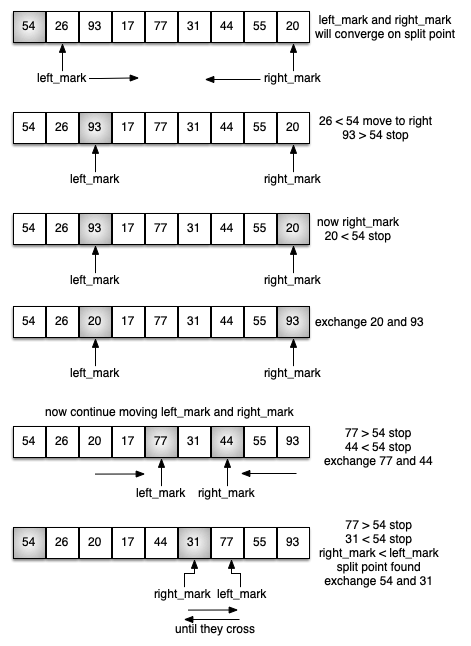

In [24]:
def quick_sort(a_list):
    """
    Main wrapper function that triggers the recursive Quick Sort
    using boundaries for the entire list.
    """
    quick_sort_helper(a_list, 0, len(a_list) - 1)


def quick_sort_helper(a_list, first, last):
    """
    Recursively segments and sorts portions of the list.
    """
    if first < last:
        # Partition the list and get the final resting position of the pivot
        split = partition(a_list, first, last)
        
        # Recursively sort the left half (items smaller than the pivot)
        quick_sort_helper(a_list, first, split - 1)
        # Recursively sort the right half (items larger than the pivot)
        quick_sort_helper(a_list, split + 1, last)


def partition(a_list, first, last):
    """
    Selects a pivot, positions elements around it, and places the pivot 
    in its final sorted split point.
    """
    # Select the first element as the pivot value
    pivot_val = a_list[first]
    
    # Initialize markers at opposite ends of the sorting boundary
    left_mark = first + 1
    right_mark = last
    done = False

    while not done:
        # Increment left_mark until finding a value greater than the pivot value
        while left_mark <= right_mark and a_list[left_mark] <= pivot_val:
            left_mark = left_mark + 1
            
        # Decrement right_mark until finding a value less than the pivot value
        while left_mark <= right_mark and a_list[right_mark] >= pivot_val:
            right_mark = right_mark - 1
            
        # Check if the markers have crossed (stopping condition)
        if right_mark < left_mark:
            done = True
        else:
            # Exchange the two out-of-place items to restore relative order
            a_list[left_mark], a_list[right_mark] = (
                a_list[right_mark],
                a_list[left_mark],
            )
            
    # At the point where right_mark becomes less than left_mark, we stop.
    # The position of right_mark is now the split point.
    # Exchange the pivot value with the contents of the split point.
    a_list[first], a_list[right_mark] = a_list[right_mark], a_list[first] # here is where we modify the list

    # Return the split point index to guide the next recursion step
    return right_mark


# Test data (Unsorted list)
a_list = [54, 26, 93, 17, 77, 31, 44, 55, 20]

# Execute the quick sort
quick_sort(a_list)

# Print the final sorted result
print(a_list)  # Output: [17, 20, 26, 31, 44, 54, 55, 77, 93]


[17, 20, 26, 31, 44, 54, 55, 77, 93]


In [23]:
def quick_sort_median(a_list):
    """
    Main wrapper function that triggers the recursive Quick Sort
    using the Median-of-Three optimization.
    """
    quick_sort_helper(a_list, 0, len(a_list) - 1)


def quick_sort_helper(a_list, first, last):
    """
    Recursively segments and sorts portions of the list.
    """
    if first < last:
        # Partition the list using Median-of-Three pivot selection
        split = partition_median(a_list, first, last)
        
        # Recursively sort the left and right partitions
        quick_sort_helper(a_list, first, split - 1)
        # Recursively sort the right half (items larger than the pivot)
        quick_sort_helper(a_list, split + 1, last)


def partition_median(a_list, first, last):
    """
    Chooses a pivot using Median-of-Three, positions elements around it,
    and returns the final split point index.
    """
    # 1. MEDIAN-OF-THREE SELECTION
    mid = (first + last) // 2
    
    # Extract the three candidate values
    val_first = a_list[first]
    val_mid = a_list[mid]
    val_last = a_list[last]
    
    # Determine which of the three is the median value
    # We find the index of the median value
    if (val_first <= val_mid <= val_last) or (val_last <= val_mid <= val_first):
        median_idx = mid
    elif (val_mid <= val_first <= val_last) or (val_last <= val_first <= val_mid):
        median_idx = first
    else:
        median_idx = last

    # 2. PIVOT POSITIONING
    # Swap the chosen median element into the 'first' position.
    # This allows the rest of our existing partition code to run completely unchanged!
    a_list[first], a_list[median_idx] = a_list[median_idx], a_list[first]

    # Now proceed with the standard partition logic
    pivot_val = a_list[first]
    left_mark = first + 1
    right_mark = last
    done = False

    while not done:
        # Increment left_mark until finding a value greater than the pivot value
        while left_mark <= right_mark and a_list[left_mark] <= pivot_val:
            left_mark = left_mark + 1
            
        # Decrement right_mark until finding a value less than the pivot value
        while left_mark <= right_mark and a_list[right_mark] >= pivot_val:
            right_mark = right_mark - 1
            
        # Check if markers have crossed
        if right_mark < left_mark:
            done = True
        else:
            # Exchange out-of-place elements
            a_list[left_mark], a_list[right_mark] = (
                a_list[right_mark],
                a_list[left_mark],
            )
            
    # Place the pivot value into its final resting split point
    a_list[first], a_list[right_mark] = a_list[right_mark], a_list[first]

    return right_mark


# Test data (Unsorted list)
a_list = [54, 26, 93, 17, 77, 31, 44, 55, 20]

# Execute the median-of-three quick sort
quick_sort_median(a_list)

# Print the final sorted result
print(a_list)  # Output: [17, 20, 26, 31, 44, 54, 55, 77, 93]


[17, 20, 26, 31, 44, 54, 55, 77, 93]


#### PlayGround

In [22]:
import time

def quick_sort(a_list):
    print("=" * 70)
    print(f"🚀 INITIALIZING QUICK SORT ON: {a_list}")
    print("=" * 70)
    quick_sort_helper(a_list, 0, len(a_list) - 1, depth=0)


def quick_sort_helper(a_list, first, last, depth):
    indent = "  " * depth
    if first < last:
        print(f"\n{indent}⬇️  Sorting sub-array segment: {a_list[first:last+1]} (Indices: {first} to {last})")
        
        # Partition the segment and find the split point
        split = partition(a_list, first, last, depth)
        
        # Recursively break down left and right segments
        quick_sort_helper(a_list, first, split - 1, depth + 1)
        quick_sort_helper(a_list, split + 1, last, depth + 1)


def partition(a_list, first, last, depth):
    indent = "  " * depth
    pivot_val = a_list[first]
    left_mark = first + 1
    right_mark = last
    done = False

    print(f"{indent}📌 Selected Pivot Value: {pivot_val} (at Index: {first})")
    print(f"{indent}🚩 Marks Initialized -> Left Mark Index: {left_mark} ('{a_list[left_mark]}'), Right Mark Index: {right_mark} ('{a_list[right_mark]}')")
    time.sleep(0.3)

    while not done:
        # Increment left_mark
        while left_mark <= right_mark and a_list[left_mark] <= pivot_val:
            left_mark = left_mark + 1
        
        # Decrement right_mark
        while left_mark <= right_mark and a_list[right_mark] >= pivot_val:
            right_mark = right_mark - 1

        # Check if markers crossed
        if right_mark < left_mark:
            print(f"{indent}❌ Markers Crossed! Left Mark is at {left_mark}, Right Mark is at {right_mark}")
            done = True
        else:
            # Swapping two out-of-place elements
            print(f"{indent}🔄 Out-of-place pair found! Swapping Index {left_mark} ({a_list[left_mark]}) ↔️ Index {right_mark} ({a_list[right_mark]})")
            a_list[left_mark], a_list[right_mark] = a_list[right_mark], a_list[left_mark]
            print(f"{indent}    Current Array State: {a_list}")
            time.sleep(0.2)

    # Swap pivot into its absolute split point
    print(f"{indent}🎯 Placing Pivot {pivot_val} into its final split point at Index {right_mark} (Swapping with {a_list[right_mark]})")
    a_list[first], a_list[right_mark] = a_list[right_mark], a_list[first]
    
    print(f"{indent}⬆️  Finished Partition. Segment State: {a_list[first:last+1]}")
    return right_mark


# Test data
a_list = [54, 26, 93, 17, 77, 31, 44, 55, 20]

# Execute execution trace
quick_sort(a_list)

print("\n" + "=" * 70)
print(f"🎉 FINAL COMPLETED SORT: {a_list}")
print("=" * 70)


🚀 INITIALIZING QUICK SORT ON: [54, 26, 93, 17, 77, 31, 44, 55, 20]

⬇️  Sorting sub-array segment: [54, 26, 93, 17, 77, 31, 44, 55, 20] (Indices: 0 to 8)
📌 Selected Pivot Value: 54 (at Index: 0)
🚩 Marks Initialized -> Left Mark Index: 1 ('26'), Right Mark Index: 8 ('20')
🔄 Out-of-place pair found! Swapping Index 2 (93) ↔️ Index 8 (20)
    Current Array State: [54, 26, 20, 17, 77, 31, 44, 55, 93]
🔄 Out-of-place pair found! Swapping Index 4 (77) ↔️ Index 6 (44)
    Current Array State: [54, 26, 20, 17, 44, 31, 77, 55, 93]
❌ Markers Crossed! Left Mark is at 6, Right Mark is at 5
🎯 Placing Pivot 54 into its final split point at Index 5 (Swapping with 31)
⬆️  Finished Partition. Segment State: [31, 26, 20, 17, 44, 54, 77, 55, 93]

  ⬇️  Sorting sub-array segment: [31, 26, 20, 17, 44] (Indices: 0 to 4)
  📌 Selected Pivot Value: 31 (at Index: 0)
  🚩 Marks Initialized -> Left Mark Index: 1 ('26'), Right Mark Index: 4 ('44')
  ❌ Markers Crossed! Left Mark is at 4, Right Mark is at 3
  🎯 Placing